### Frequency content of reconstructed subbands

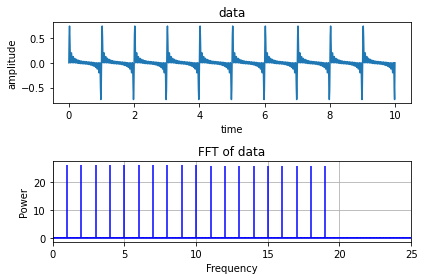

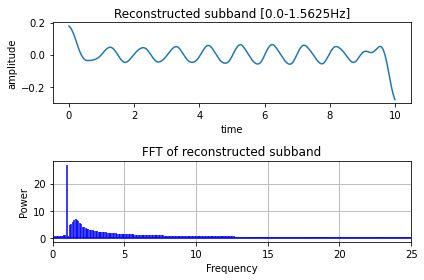

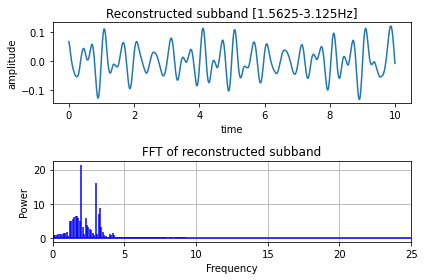

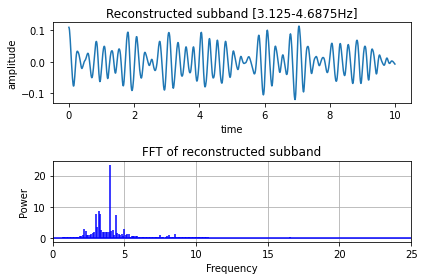

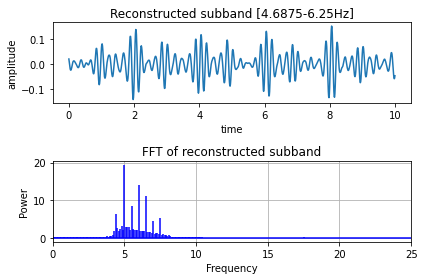

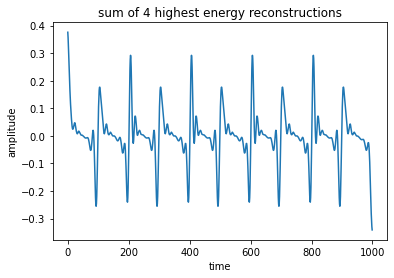

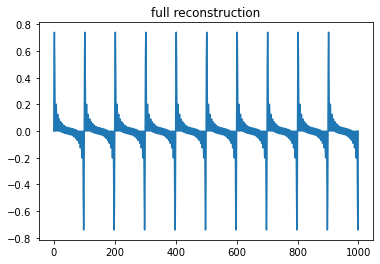

In [2]:
import sys
sys.path.append('..')

from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv

import matplotlib.pyplot as plt
import numpy as np

# keep the same
sampling_rate = 100

# PARAMETERS TO CHANGE
frequencies = list(np.arange(1,20)) # frequency content of wave
duration = 10/min(frequencies) # duration of wave
fft_lim = int(sampling_rate/4) # limit of x-axis in fft plot

wavelet = 'db10'
levels = 5
mode = 'symmetric'

sort_by_energy = False # plot reconstructions of top 'n_highest' subbands by energy
n_highest = 4 # set sort_by_energy to False to plot subbands in increasing order of frequency

# generate sound wave
data,t_plot = sd.sound_wave(1/len(frequencies),frequencies,duration,sampling_rate)
# data += np.random.normal(0,0.2,len(data))
freq = np.linspace(0,sampling_rate,len(data))
fft_data = np.fft.fft(data)

# plot sound wave and fft
fig,ax = plt.subplots(2)
ax[0].plot(t_plot,data)
ax[0].set_title('data')
ax[0].set_xlabel('time')
ax[0].set_ylabel('amplitude')
ax[1].stem(freq, np.abs(fft_data), linefmt='b', markerfmt=" ", basefmt="-b")
ax[1].set_title('FFT of data')
ax[1].set_xlabel('Frequency')
ax[1].set_ylabel('Power')
ax[1].set_xlim(0,fft_lim)
ax[1].grid()
fig.tight_layout()
plt.show()

# transform
tr_ob = wpt.dwpt(data,levels,wavelet)
tr_ob.calc_frequencies(sampling_rate)

# reconstruct each node separately
coeffs = []
rec = []

for node in tr_ob.get_level(order='freq'):
    path = node.path
    rec_nodes = tr_ob.packet_nodes_for_rec(keep=[path])
    coeffs.append(tr_ob.nodes2data(rec_nodes))
    inverse = inv.inv_dwpt(coeffs[-1],wavelet)[:len(data)]
    fft = np.fft.fft(inverse)
    rec.append((node,inverse,fft))

# order reconstructed waves
if sort_by_energy:
    rec.sort(key=lambda x:sum(np.array(x[1])**2),reverse=True) # SUPPRESS TO PLOT SUBBANDS IN ORDER

# plot highest energy subbands
x = np.zeros(len(data)) # track sum of highest energy subbands
for i in range(len(rec)):
    node,rec_wave,fft = rec[i] 
    if i in range(n_highest) or node.match_ids(frequencies): # highest energy + freqs of interest
        x+=rec_wave
        fig,ax = plt.subplots(2)
        freq_r = node.frequency_range
        ax[0].plot(t_plot,rec_wave)
        ax[0].set_title(f'Reconstructed subband [{freq_r[0]}-{freq_r[1]}Hz]')
        ax[0].set_xlabel('time')
        ax[0].set_ylabel('amplitude')
        ax[1].stem(freq, np.abs(fft), linefmt='b', markerfmt=" ", basefmt="-b")
        ax[1].set_title(f'FFT of reconstructed subband')
        ax[1].set_xlabel('Frequency')
        ax[1].set_ylabel('Power')
        ax[1].set_xlim(0,fft_lim)
        ax[1].grid()
        fig.tight_layout()
        plt.show()

# plot sum of highest energy subbands
plt.plot(x)
plt.xlabel('time')
plt.ylabel('amplitude')
plt.title(f'sum of {n_highest} highest energy reconstructions')
plt.show()

# plot full reconstruction
full_rec = inv.inv_dwpt(tr_ob.nodes2data(tr_ob.get_level()),wavelet)
plt.plot(full_rec[:len(data)])
plt.title('full reconstruction')
plt.show()

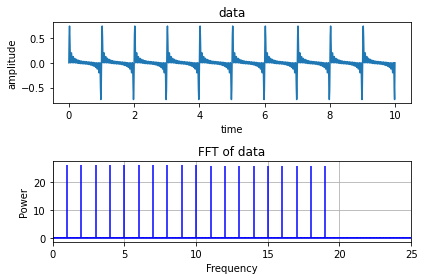

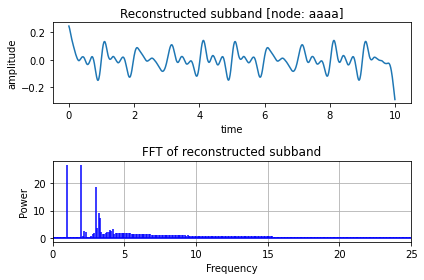

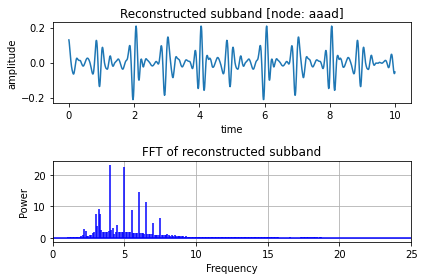

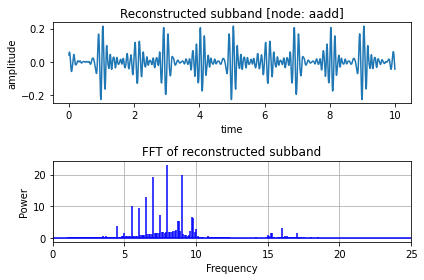

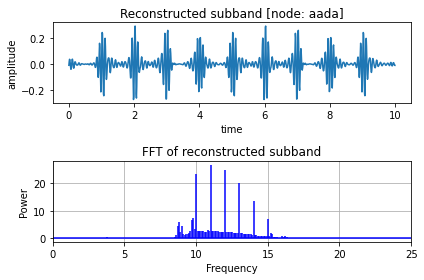

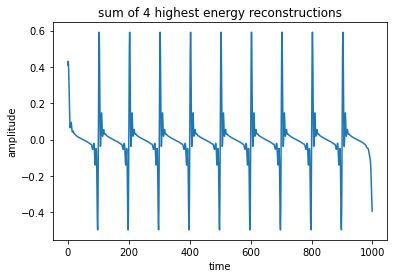

In [16]:
import pywt
# plot sound wave and fft
fig,ax = plt.subplots(2)
ax[0].plot(t_plot,data)
ax[0].set_title('data')
ax[0].set_xlabel('time')
ax[0].set_ylabel('amplitude')
ax[1].stem(freq, np.abs(fft_data), linefmt='b', markerfmt=" ", basefmt="-b")
ax[1].set_title('FFT of data')
ax[1].set_xlabel('Frequency')
ax[1].set_ylabel('Power')
ax[1].set_xlim(0,fft_lim)
ax[1].grid()
fig.tight_layout()
plt.show()

# transform
wp = pywt.WaveletPacket(data,wavelet,mode)

# reconstruct each node separately
coeffs = []
rec = []

for node in wp.get_level(levels,'freq'):
    path = node.path
    rec_nodes = tr_ob.packet_nodes_for_rec(keep=[path])
    coeffs.append(tr_ob.nodes2data(rec_nodes))
    inverse = inv.inv_dwpt(coeffs[-1],wavelet)[:len(data)]
    fft = np.fft.fft(inverse)
    rec.append((node,inverse,fft))

# order reconstructed waves
if sort_by_energy:
    rec.sort(key=lambda x:sum(np.array(x[1])**2),reverse=True) # SUPPRESS TO PLOT SUBBANDS IN ORDER

# plot highest energy subbands
x = np.zeros(len(data)) # track sum of highest energy subbands
for i in range(len(rec)):
    node,rec_wave,fft = rec[i] 
    if i in range(n_highest): # highest energy + freqs of interest
        x+=rec_wave
        fig,ax = plt.subplots(2)
        ax[0].plot(t_plot,rec_wave)
        ax[0].set_title(f'Reconstructed subband [node: {node.path}]')
        ax[0].set_xlabel('time')
        ax[0].set_ylabel('amplitude')
        ax[1].stem(freq, np.abs(fft), linefmt='b', markerfmt=" ", basefmt="-b")
        ax[1].set_title(f'FFT of reconstructed subband')
        ax[1].set_xlabel('Frequency')
        ax[1].set_ylabel('Power')
        ax[1].set_xlim(0,fft_lim)
        ax[1].grid()
        fig.tight_layout()
        plt.show()

# plot sum of highest energy subbands
plt.plot(x)
plt.xlabel('time')
plt.ylabel('amplitude')
plt.title(f'sum of {n_highest} highest energy reconstructions')
plt.show()

### frequency ranges

checking if the frequency ranges are calculated correctly

In [13]:
for node in tr_ob.get_level(2):
    print(f'{node.path} ({node.level},{node.node_number()}) {node.frequency_range}')

aa (2,0) (0.0, 12.5)
ad (2,1) (12.5, 25.0)
da (2,2) (25.0, 37.5)
dd (2,3) (37.5, 50.0)


In [18]:
import pywt
print(pywt._wavelet_packets.get_graycode_order(3))
print(pywt._wavelet_packets.get_graycode_order(4))

['aaa', 'aad', 'add', 'ada', 'dda', 'ddd', 'dad', 'daa']
['aaaa', 'aaad', 'aadd', 'aada', 'adda', 'addd', 'adad', 'adaa', 'ddaa', 'ddad', 'dddd', 'ddda', 'dada', 'dadd', 'daad', 'daaa']
